# Avocados Analysis

Sklearn can be very useful for data analysis in Python/Jupyter

## Information obtained from Kaggle

#### Project done by Miguel Estrada

In [44]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix
from sklearn.metrics import accuracy_score
from sklearn.inspection import permutation_importance
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
import numpy as np
# Import SMOTE
from imblearn.over_sampling import SMOTE

In [45]:
#Importing the data
data_avocados = pd.read_csv('avocado_ripeness_dataset.csv')
data_avocados.head(2)

,firmness,hue,saturation,brightness,color_category,sound_db,weight_g,size_cm3,ripeness
0,14.5,19,40,26,black,34,175,261,ripe
1,71.7,53,69,75,green,69,206,185,pre-conditioned


In [46]:
data_avocados.isna().sum()

firmness          0
hue               0
saturation        0
brightness        0
color_category    0
sound_db          0
weight_g          0
size_cm3          0
ripeness          0
dtype: int64

In [47]:
data_avocados.isnull().sum()

firmness          0
hue               0
saturation        0
brightness        0
color_category    0
sound_db          0
weight_g          0
size_cm3          0
ripeness          0
dtype: int64

In [48]:
data_avocados.color_category.value_counts()

color_category
black         75
purple        75
green         50
dark green    50
Name: count, dtype: int64

In [49]:
data_avocados.ripeness.value_counts()

ripeness
ripe               50
pre-conditioned    50
hard               50
breaking           50
firm-ripe          50
Name: count, dtype: int64

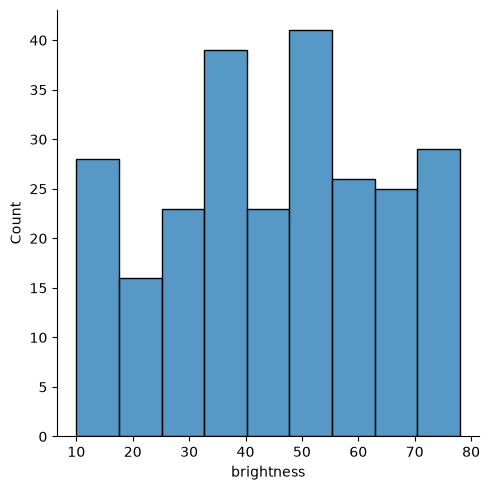

In [50]:
sns.displot(data_avocados['brightness'], kde=False)

<Axes: xlabel='weight_g', ylabel='size_cm3'>

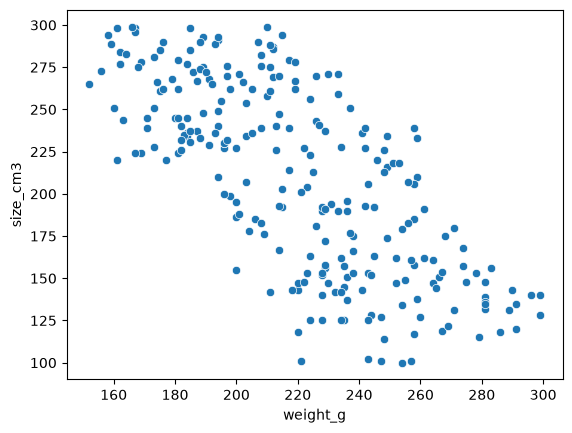

In [51]:
sns.scatterplot(x=data_avocados['weight_g'], y=data_avocados['size_cm3'])

<Axes: xlabel='weight_g', ylabel='brightness'>

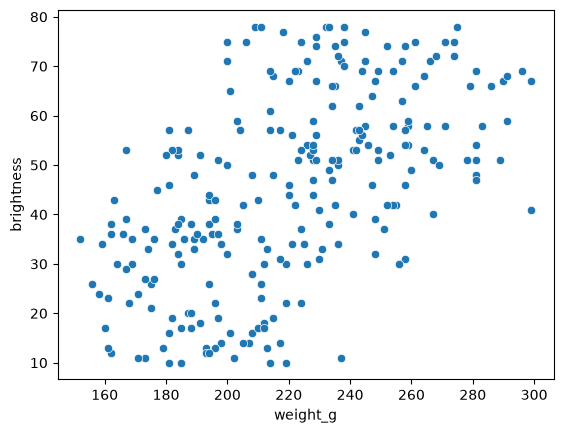

In [52]:
sns.scatterplot(x=data_avocados['weight_g'], y=data_avocados['brightness'])

#### Preparing data for Logistic Regression
Used for predicting the ripeness of the avocado

In [53]:
X = data_avocados.drop('ripeness', axis=1)
Y = data_avocados['ripeness']

In [54]:
from sklearn.preprocessing import LabelEncoder
labelencoder = LabelEncoder()
Y = labelencoder.fit_transform(Y)

X.color_category = labelencoder.fit_transform(X.color_category.values)

In [55]:
x_train, x_test, y_train, y_test = train_test_split(X, Y, test_size=0.25)

In [56]:
sc = StandardScaler()
x_train = sc.fit_transform(x_train)
x_test = sc.fit_transform(x_test)

## Synthetic Minority Over-sampling Technique
Applied with Python

In [57]:
smote = SMOTE(random_state=42)
x_train_smote, y_train_smote = smote.fit_resample(x_train, y_train)

In [58]:
classifier = LogisticRegression(fit_intercept=True)
classifier.fit(x_train_smote, y_train_smote)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default sol

In [59]:
predictions = classifier.predict(x_test)

### Feature importance
This section measures how much each column contributes to the model's predictions.

In [61]:
# Keep the original column names for the importance results.
feature_names = X.columns

from sklearn.metrics import make_scorer, roc_auc_score

multiclass_roc_auc = make_scorer(
    roc_auc_score,
    multi_class='ovr',   # or 'ovo'
    average='macro',     # or 'weighted'
    response_method='predict_proba'
)

permutation_result = permutation_importance(
    classifier,
    x_test,
    y_test,
    n_repeats=30,
    random_state=42,
    scoring=multiclass_roc_auc,
    n_jobs=-1
)

permutation_importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance Mean': permutation_result.importances_mean,
    'Importance Std': permutation_result.importances_std
})

permutation_importance_df = permutation_importance_df.sort_values(
    by='Importance Mean',
    ascending=False
).reset_index(drop=True)

permutation_importance_df

,Feature,Importance Mean,Importance Std
0,hue,0.074210,0.019563
1,sound_db,0.058928,0.009277
2,color_category,0.032345,0.013911
3,firmness,0.024329,0.011343
4,brightness,0.006320,0.003106
5,size_cm3,0.004516,0.002664
6,saturation,0.000012,0.000063
7,weight_g,0.000000,0.000000


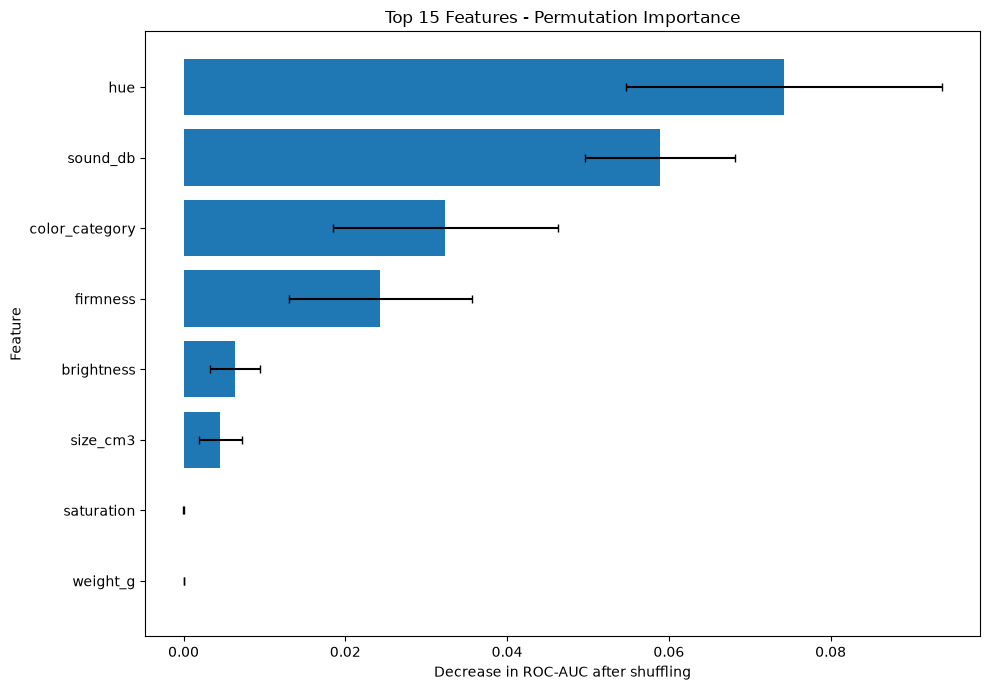

In [62]:
# Plot the 15 most important features.
top_features = permutation_importance_df.head(15).sort_values(
    by='Importance Mean',
    ascending=True
)

plt.figure(figsize=(10, 7))
plt.barh(
    top_features['Feature'],
    top_features['Importance Mean'],
    xerr=top_features['Importance Std'],
    capsize=3
)
plt.xlabel('Decrease in ROC-AUC after shuffling')
plt.ylabel('Feature')
plt.title('Top 15 Features - Permutation Importance')
plt.tight_layout()
plt.show()

### Logistic Regression Coefficients
Positive coefficients indicate that higher values of a feature are associated with a higher predicted probability of Outcome = 1, while negative coefficients indicate the opposite.

The absolute coefficient value represents its magnitude, not proof of causation. Correlated features can share or redistribute importance.

In [66]:
coefficient_df = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': classifier.coef_[0]
})

coefficient_df['Absolute Coefficient'] = coefficient_df['Coefficient'].abs()

coefficient_df = coefficient_df.sort_values(
    by='Absolute Coefficient',
    ascending=False
).reset_index(drop=True)

coefficient_df

,Feature,Coefficient,Absolute Coefficient
0,hue,1.849578,1.849578
1,sound_db,1.657359,1.657359
2,color_category,1.315939,1.315939
3,firmness,1.269653,1.269653
4,brightness,-0.481810,0.481810
5,saturation,-0.096035,0.096035
6,weight_g,0.089972,0.089972
7,size_cm3,-0.081391,0.081391


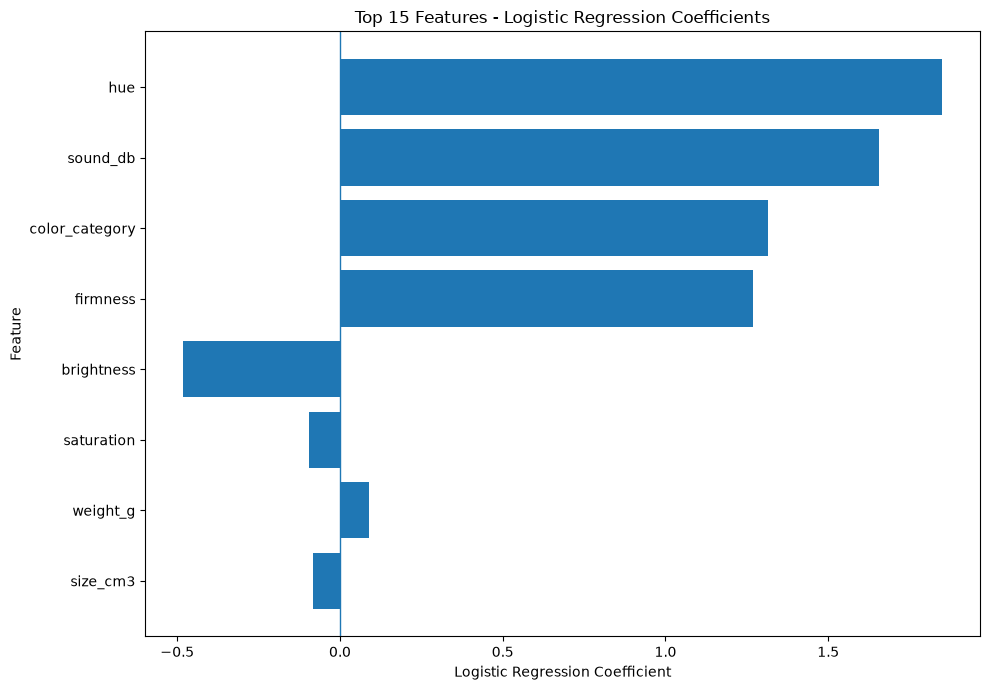

In [67]:
# Plot the 15 features with the largest absolute coefficients.
top_coefficients = coefficient_df.head(15).sort_values(
    by='Absolute Coefficient',
    ascending=True
)

plt.figure(figsize=(10, 7))
plt.barh(
    top_coefficients['Feature'],
    top_coefficients['Coefficient']
)
plt.axvline(x=0, linewidth=1)
plt.xlabel('Logistic Regression Coefficient')
plt.ylabel('Feature')
plt.title('Top 15 Features - Logistic Regression Coefficients')
plt.tight_layout()
plt.show()

## There is a very big precision due to the correlation in the data

In [63]:
from sklearn.metrics import classification_report
print(classification_report(y_test, predictions))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        14
           1       1.00      1.00      1.00        11
           2       1.00      1.00      1.00        11
           3       1.00      1.00      1.00        13
           4       1.00      1.00      1.00        14

    accuracy                           1.00        63
   macro avg       1.00      1.00      1.00        63
weighted avg       1.00      1.00      1.00        63



<Axes: >

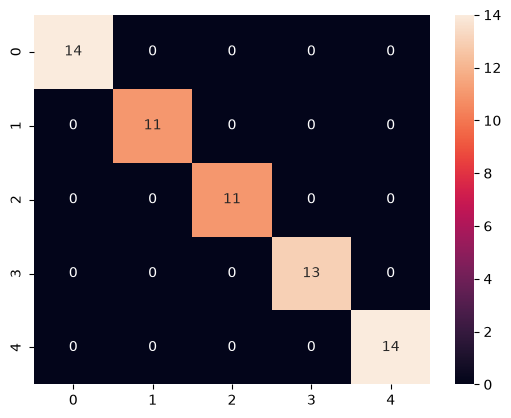

In [60]:
cm = confusion_matrix(y_test, predictions)
sns.heatmap(cm, annot=True)

In [64]:
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

mean_squared_error_ = mean_squared_error(y_test, predictions)
r2_score_ = r2_score(y_test, predictions)
mean_absolute_error_ = mean_absolute_error(y_test, predictions)

print("Mean Squared Error: {}".format(mean_squared_error_))
print("R2 score: {}".format(r2_score_))
print("Mean Absolute Error: {}".format(mean_absolute_error_))

Mean Squared Error: 0.0
R2 score: 1.0
Mean Absolute Error: 0.0


In [65]:
## Accuracy of the model
accuracy_score(y_test, predictions)

1.0